# Clindent data preprocessing

Synchronize `Force.csv` and `LVDT.csv`, repair short native LVDT spikes, and export synchronized force and displacement for each indentation cycle. Run all cells with the **Dataprocess** environment. The default input is `data/Clindent_Data/400g/Black_Gel/sample_01/`, including `Trial_01` through `Trial_07`. Change `INPUT_DIR` to select another load, material, or sample; `TRIAL_NAMES = None` discovers raw trials within that sample.

Set `ENABLE_STEADY_STATE_SEGMENTATION = True` to export only the detected steady-force interval. Set it to `False` to export the full loading and hold interval, from the displacement threshold for the first cycle, or the **moving to bottom** command for later cycles, until the **moving to top** command starts unloading. Set `EXPORT_DURATION_S = 60.0` to retain exactly 60 seconds from the first selected sample in either mode; leave it as `None` to retain the whole selected interval. If no sequence log exists, force-based detection estimates the cycle boundaries using the configured pre-trigger and release guard.

Each output CSV has exactly these columns: **`Time, s`**, **`Indentation Position, mm`**, **`Indentation Force, N`**. Both signals use **linear interpolation at 200 Hz** (0.005 s spacing) on a common grid. Each exported cycle starts at `Time, s = 0` at its first retained sample in either segmentation mode, with 0.005 s spacing. Original trial timing remains in the manifest. Three cycles from `Trial_01` become `Trial_01_1.csv`, `Trial_01_2.csv`, and `Trial_01_3.csv` in `data/Clindent_Data/400g/Black_Gel/sample_01/synchronized/Indentation_01/`, `Indentation_02/`, and `Indentation_03/`, respectively. The same cycle number from every trial shares one folder.

Review the plots before running the final export cell. This notebook does not fit a model.

Tables and plot labels retain two significant digits in the fractional part, ignoring leading fractional zeros (for example, 4.001234 becomes 4.0012 and 0.001234 becomes 0.0012). Exported force and displacement use two decimal places; timestamps and interval boundaries retain their precision to preserve 200 Hz sampling. Calculations use full precision before export. Rounding displacement to 0.01 mm can affect later fits of small creep changes.


## Single-sample or batch selection

Keep `SAMPLE_NAMES = None` to use the configured `INPUT_DIR`. Set `SAMPLE_NAMES = ['sample_01', 'sample_02', 'sample_03']` to process the three sibling sample directories in one Run All; a one-item list selects another single sample. Settings and `TRIAL_NAMES` apply to every selected sample. CSVs, manifests, obsolete-export cleanup, and optional figures remain scoped to each sample's own `synchronized/` directory. Diagnostic labels include the sample in batch mode. All selected samples must contain raw trials; a missing or empty sample stops processing before any export. Run all cells again after changing the selection.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

from IPython.display import display



def find_project_root(start):
    for candidate in (start, *start.parents):
        if (candidate / 'data_process' / 'utils' / 'creep_force_preprocessing.py').is_file():
            return candidate
    raise FileNotFoundError('Start the notebook from within the Tonometry_Control_Code project.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
sys.path.insert(0, str(PROJECT_ROOT / 'data_process' / 'utils'))
from notebook_formatting import format_fractional_digits
from notebook_samples import select_sample_dirs

pd.options.display.float_format = format_fractional_digits
from creep_force_preprocessing import (
    OUTPUT_COLUMNS, load_trial, detect_indentation_cycles, segment_force_steady_state,
    extract_indentation_cycles,
)

INPUT_DIR = PROJECT_ROOT / 'data' / 'Clindent_Data' / '400g' / 'Black_Gel' / 'sample_01'
OUTPUT_DIR = INPUT_DIR / 'synchronized'
SAMPLE_NAMES = None  # Use ['sample_01', 'sample_02', 'sample_03'] to process all three.
SAMPLE_DIRS = select_sample_dirs(INPUT_DIR, SAMPLE_NAMES)
OUTPUT_DIRS = ([OUTPUT_DIR] if SAMPLE_NAMES is None
               else [directory / 'synchronized' for directory in SAMPLE_DIRS])
output_dir_by_sample = dict(zip(SAMPLE_DIRS, OUTPUT_DIRS))
TRIAL_NAMES = None  # Discover raw trial directories within the selected sample.
# TRIAL_NAMES = ['Trial_01']
SAMPLING_HZ = 200.0
DT_S = 1.0 / SAMPLING_HZ
ENABLE_FORCE_LOWPASS = True  # Load Cell Low-pass filter: Yes.
FORCE_LOWPASS_ORDER = 3  # Butterworth order per pass; forward-backward filtering doubles the order.
FORCE_LOWPASS_CUTOFF_HZ = 20.0  # Single-pass cutoff frequency in Hz.
BASELINE_S = 0.15
MAX_INTERPOLATION_GAP_S = 0.2
FORCE_AXIS = 'Fz'
COMPRESSION_SIGN = -1.0
DISPLACEMENT_SIGN = 1.0
DISPLACEMENT_DESPIKE_SETTINGS = dict(
    window_s=0.2, threshold=0.12, n_sigma=6.0, max_duration_s=0.06, max_gap_s=0.2,
)
CYCLE_METHOD = 'force'  # Prefer sequence logs; alternatives: 'sequence' or 'force'.
FORCE_SEGMENTATION_SETTINGS = dict(
    min_force_n=0.2, on_fraction=0.2, off_fraction=0.1, onset_fraction=0.02,
    debounce_s=0.1, min_loaded_s=5.0, smoothing_s=0.1,
)
FORCE_RELEASE_GUARD_S = 0.3  # Conservative trimming for force-only boundary estimates.
FORCE_PRE_INDENT_S = 0.2  # Preserve the initial ramp in the force-only fallback.
ENABLE_STEADY_STATE_SEGMENTATION = True  # False keeps the full loading and hold interval.
EXPORT_DURATION_S = 118.5  # Set to 60.0 for a 60-second export in either mode.
FORCE_STEADY_STATE_SETTINGS = dict(
    stability_window_s=0.5, stable_confirm_s=0.5, plateau_tail_s=5.0,
    level_tolerance_fraction=0.05, stable_std_fraction=0.03,
    stable_slope_fraction=0.05, release_guard_s=0.25, min_force_n=0.2,
)
# Shared across all trials/cycles: seconds from cycle onset; None uses automatic detection.
STEADY_START_TIME_S = None  # Example: 1.0; replaces the automatic start and its offset.
# Used only with steady-state segmentation: positive delays, negative advances.
STEADY_START_OFFSET_S = 0.0
STEADY_END_OFFSET_S = 0.0
SAVE_FIGURES = False
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.25})


def show_figure(fig, filename, output_dir):
    for axis in fig.axes:
        for coordinate in ('xaxis', 'yaxis', 'zaxis'):
            if hasattr(axis, coordinate):
                getattr(axis, coordinate).set_major_formatter(format_fractional_digits)
    fig.tight_layout()
    if SAVE_FIGURES:
        figure_dir = output_dir / 'figures'
        figure_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(figure_dir / filename, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)


print(f'Inputs: {SAMPLE_DIRS}')
print(f'Outputs: {OUTPUT_DIRS}')
print(f'Sampling: {SAMPLING_HZ:g} Hz; linear interpolation; dt = {DT_S:g} s')
print(f'Force low-pass filter: {ENABLE_FORCE_LOWPASS}; order per pass: {FORCE_LOWPASS_ORDER}; '
      f'single-pass cutoff: {FORCE_LOWPASS_CUTOFF_HZ:g} Hz; zero-phase Butterworth')
print(f'Steady-state segmentation: {ENABLE_STEADY_STATE_SEGMENTATION}')
print(f'Export duration: {EXPORT_DURATION_S} s')

Inputs: [PosixPath('/Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Clindent_Data/400g/Black_Gel/sample_01')]
Outputs: [PosixPath('/Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Clindent_Data/400g/Black_Gel/sample_01/synchronized')]
Sampling: 200 Hz; linear interpolation; dt = 0.005 s
Force low-pass filter: True; order per pass: 3; single-pass cutoff: 20 Hz; zero-phase Butterworth
Steady-state segmentation: True
Export duration: 118.5 s


## Clean native samples and synchronize

Use the recorded integer nanosecond timestamps with one shared origin, rather than aligning separate `elapsed_time` columns. Mask invalid LVDT voltages outside `(0.1, 9.99)` V. Repair only short returning excursions on the native LVDT timeline using linear interpolation; retain genuine steps. Do not despike force. After synchronization, apply the configured force low-pass filter before cycle identification, steady-force detection, interval selection, or export.

Subtract the mean of the first 0.15 s from each native signal, then apply the configured signs so compression and indentation are positive. Preserve this **single trial-wide baseline** in every exported cycle, including residual indentation in later cycles. Do not zero displacement independently for each export. After synchronization, locate the first sample with original `time_s > BASELINE_S` and corrected displacement `> 0.01 mm`. Shift native and synchronized times to that sample and update the shared timestamp origin, retaining pre-onset samples at negative times. Use time zero as the first cycle onset; detect later cycle onsets and all release boundaries with the existing sequence or force method. Raise an error if no threshold crossing exists.

Interpolate both cleaned signals directly from native samples onto the shared 200 Hz grid over their overlapping acquisition interval. There is no bin averaging or median resampling. Do not extrapolate or bridge sensor gaps longer than 0.2 s; reject any retained interval containing an unresolved gap rather than deleting grid rows.

The global settings `ENABLE_FORCE_LOWPASS = True`, `FORCE_LOWPASS_ORDER = 3`, and `FORCE_LOWPASS_CUTOFF_HZ = 20.0` enable a Butterworth low-pass filter on the synchronized force. `sosfiltfilt` applies it forward and backward to avoid phase delay: the configured order and cutoff describe each single pass, and the combined response has twice the order and about -6 dB attenuation at that cutoff. These settings do not establish equivalence with the Biomomentum instrument's filter implementation. Filter each continuous finite force interval independently, before cutting cycles; missing samples remain missing. Intervals too short for filter padding raise an error. Set `ENABLE_FORCE_LOWPASS = False` to bypass filtering. Rerun from the configuration cell after changing any filter setting. Native XYZ diagnostics retain the unfiltered samples.

In [2]:
if ENABLE_FORCE_LOWPASS:
    if (isinstance(FORCE_LOWPASS_ORDER, (bool, np.bool_))
            or not isinstance(FORCE_LOWPASS_ORDER, (int, np.integer))
            or FORCE_LOWPASS_ORDER < 1):
        raise ValueError('FORCE_LOWPASS_ORDER must be a positive integer.')
    if not np.isfinite(FORCE_LOWPASS_CUTOFF_HZ) or not (
            0 < FORCE_LOWPASS_CUTOFF_HZ < SAMPLING_HZ / 2):
        raise ValueError('FORCE_LOWPASS_CUTOFF_HZ must be finite, positive, and below SAMPLING_HZ / 2.')
    force_lowpass_sos = butter(
        FORCE_LOWPASS_ORDER, FORCE_LOWPASS_CUTOFF_HZ,
        btype='lowpass', fs=SAMPLING_HZ, output='sos',
    )

if TRIAL_NAMES is not None and (not TRIAL_NAMES or len(TRIAL_NAMES) != len(set(TRIAL_NAMES))):
    raise ValueError('TRIAL_NAMES must be None or a nonempty list without duplicates.')
trial_dirs = []
for sample_dir in SAMPLE_DIRS:
    if TRIAL_NAMES is None:
        directories = sorted(
            path for path in sample_dir.iterdir()
            if path.is_dir() and (path / 'Force.csv').is_file() and (path / 'LVDT.csv').is_file()
        )
    else:
        directories = [sample_dir / name for name in TRIAL_NAMES]
    if not directories:
        raise FileNotFoundError(f'No raw Clindent trials were found in {sample_dir}.')
    trial_dirs.extend(directories)
trial_labels = {path: (f'{path.parent.name}__{path.name}' if len(SAMPLE_DIRS) > 1 else path.name)
                for path in trial_dirs}
assert len(set(trial_labels.values())) == len(trial_dirs), 'Trial labels must be unique across samples.'

processed = []
quality_rows = []
for trial_dir in trial_dirs:
    trial = load_trial(
        trial_dir, dt=DT_S, baseline_s=BASELINE_S, max_gap_s=MAX_INTERPOLATION_GAP_S,
        force_axis=FORCE_AXIS, compression_sign=COMPRESSION_SIGN,
        displacement_sign=DISPLACEMENT_SIGN,
        displacement_despike=DISPLACEMENT_DESPIKE_SETTINGS, force_despike=None,
    )
    if ENABLE_FORCE_LOWPASS:
        force = trial['sync'].force_n.to_numpy(copy=True)
        # Keep unresolved gaps from contaminating other continuous force intervals.
        edges = np.flatnonzero(np.diff(np.r_[False, np.isfinite(force), False]))
        for start, stop in edges.reshape(-1, 2):
            try:
                force[start:stop] = sosfiltfilt(force_lowpass_sos, force[start:stop])
            except ValueError as exc:
                raise ValueError(f'{trial_labels[trial_dir]}: Cannot filter force interval '
                                 f'[{start}:{stop}] ({stop - start} samples): {exc}') from exc
        trial['sync']['force_n'] = force
    cycles = detect_indentation_cycles(
        trial_dir, trial, method=CYCLE_METHOD, force_settings=FORCE_SEGMENTATION_SETTINGS,
        force_release_guard_s=FORCE_RELEASE_GUARD_S, force_pre_indent_s=FORCE_PRE_INDENT_S,
    )
    if cycles.onset_s.min() + trial['time_zero_s'] < BASELINE_S:
        raise ValueError(f'{trial_labels[trial_dir]}: Shorten BASELINE_S so it ends before indentation.')
    processed.append(dict(name=trial_dir.name, label=trial_labels[trial_dir],
                          sample=trial_dir.parent.name, output_dir=output_dir_by_sample[trial_dir.parent],
                          source=trial_dir, trial=trial, cycles=cycles))
    quality_rows.append({
        'sample': trial_dir.parent.name, 'trial': trial_labels[trial_dir], 'force_samples': len(trial['force']),
        'lvdt_samples': len(trial['lvdt']),
        'invalid_lvdt_samples': int((~trial['lvdt'].sensor_valid).sum()),
        'repaired_lvdt_spikes': int(trial['lvdt'].displacement_spike.sum()),
        'unresolved_grid_samples': int((~trial['sync'].valid).sum()),
        'detected_cycles': len(cycles),
    })

quality_summary = pd.DataFrame(quality_rows)
display(quality_summary)

,sample,trial,force_samples,lvdt_samples,invalid_lvdt_samples,repaired_lvdt_spikes,unresolved_grid_samples,detected_cycles
0,sample_01,Trial_01,53403,28835,0,24,0,1
1,sample_01,Trial_02,61297,32694,9,51,0,1
2,sample_01,Trial_03,61357,33845,0,67,0,1
3,sample_01,Trial_04,61296,34598,9,65,0,1
4,sample_01,Trial_05,61241,34362,18,71,0,1
5,sample_01,Trial_06,61417,34791,0,60,0,1
6,sample_01,Trial_07,61341,33837,0,69,0,1


## Select the export interval

With `ENABLE_STEADY_STATE_SEGMENTATION = False`, retain the entire detected cycle (`onset_s <= time_s < release_s`). Skip steady-force detection, its release guard, and both `STEADY_*_OFFSET_S` adjustments. Loading and settling remain in the export; unloading and recovery are excluded. Missing sensor values anywhere in the retained interval still raise an error. Force-only cycle detection retains its configured pre-trigger and release guard.

With `ENABLE_STEADY_STATE_SEGMENTATION = True`, use the following steady-force selection. In either mode, set `EXPORT_DURATION_S` to a multiple of 0.005 s (for example, `60.0`) to retain that many seconds from the first selected sample. A 60 s export contains 12,000 samples with timestamps from 0 to 59.995 s. `None` keeps the whole selected interval. If the interval is too short, selection raises an error before export. For 60 s steady-force exports from the current trials, also set `STEADY_START_OFFSET_S = 0.0`; a delayed start can leave steady intervals too short.

Within each detected indentation cycle, estimate the holding force from the median of the last `plateau_tail_s` seconds before the guarded release boundary. A full trailing `stability_window_s` window must have a mean within `level_tolerance_fraction` of that level, a standard deviation no greater than `stable_std_fraction` of the level, and an absolute linear-regression slope no greater than `stable_slope_fraction` times the level per second. The defaults are **0.5 s**, **5%**, **3%**, and **5%/s**, respectively. These statistics only detect boundaries; the exported force retains the configured low-pass filtering without additional smoothing from these statistics.

Require those conditions continuously for `stable_confirm_s` (default **0.5 s**). Start the export at the first qualifying window endpoint in that confirmed run. Keep one continuous interval until `release_guard_s` (default **0.25 s**) before release, or end earlier at the start of a later sustained loss of force stability. Shorter fluctuations remain in the continuous record. Never concatenate separated intervals or delete individual rows to hide sensor gaps. A cycle without a confirmed steady-force interval raises an error.

After automatic detection, `STEADY_START_OFFSET_S` and `STEADY_END_OFFSET_S` shift the left and right boundaries for every trial and cycle. Positive values delay a boundary; negative values advance it. For example, start `-0.5` and end `1.0` include 0.5 s earlier and 1.0 s later than the detected interval. A manual extension can include non-steady force. The adjusted interval must remain within the indentation command and release boundaries, contain at least two samples, and contain no missing sensor values; invalid adjustments raise an error rather than being clipped. Selection uses the existing 200 Hz grid: the first retained timestamp is at or after the adjusted start, and the end is exclusive. Rerun the selection and plotting cells after changing the option or offsets, then review the plots before exporting. The manifest records detected boundaries, offsets, and adjusted boundaries.

Export the displacement and measured force at exactly the same retained timestamps. Reset time only to zero at the first retained sample of each exported cycle in either mode. Preserve the trial-wide displacement and force baselines. Original command times, export boundaries, and the selected mode are recorded in `_cycle_manifest.csv`. Steady-force boundaries, holding force, offsets, and detection settings are recorded only when steady-state segmentation is enabled.

Set `STEADY_START_TIME_S = 1.0` to start every selected cycle in every trial 1 second after that cycle's `onset_s`. Clindent cycle time starts at the detected indentation onset, rather than the raw acquisition start. `None` preserves automatic start selection. This shared manual start replaces `STEADY_START_OFFSET_S` for all trials and cycles. The end still uses automatic steady-state detection plus `STEADY_END_OFFSET_S`, followed by any `EXPORT_DURATION_S` limit. Automatic detection must still find a confirmed steady interval. The manually selected interval can include loading or settling samples; its start must precede the adjusted end and remain within the cycle. The setting is ignored when segmentation is disabled. The manifest records the requested `steady_start_time_s` relative to cycle onset and an effective start offset of zero in manual mode. Rerun the configuration, selection, and all following cells, then review the plots before export.


In [3]:
if EXPORT_DURATION_S is not None and (
        not np.isfinite(EXPORT_DURATION_S) or EXPORT_DURATION_S < 2 * DT_S
        or not np.isclose(EXPORT_DURATION_S * SAMPLING_HZ,
                          round(EXPORT_DURATION_S * SAMPLING_HZ), rtol=0, atol=1e-8)):
    raise ValueError('EXPORT_DURATION_S must be at least two samples and a multiple of the sampling interval.')
if ENABLE_STEADY_STATE_SEGMENTATION and not np.isfinite(
        [STEADY_START_OFFSET_S, STEADY_END_OFFSET_S]).all():
    raise ValueError('Steady-state boundary offsets must be finite seconds.')

if ENABLE_STEADY_STATE_SEGMENTATION and STEADY_START_TIME_S is not None and (
        not np.isfinite(STEADY_START_TIME_S) or STEADY_START_TIME_S < 0):
    raise ValueError('STEADY_START_TIME_S must be None or finite nonnegative seconds.')

segment_label = 'steady-force' if ENABLE_STEADY_STATE_SEGMENTATION else 'full-load'
cycle_rows = []
for result in processed:
    trial, trial_dir = result['trial'], result['source']
    # Discard prior selections so changing modes cannot reuse stale steady boundaries.
    cycles = result['cycles'][['cycle', 'onset_s', 'release_s', 'boundary_source']].copy()
    if ENABLE_STEADY_STATE_SEGMENTATION:
        cycles = segment_force_steady_state(
            trial['sync'], cycles, **FORCE_STEADY_STATE_SETTINGS,
        )
        cycles['detected_steady_start_s'] = cycles.steady_start_s
        cycles['detected_steady_end_s'] = cycles.steady_end_s
        cycles['steady_start_s'] += STEADY_START_OFFSET_S
        cycles['steady_end_s'] += STEADY_END_OFFSET_S
        if STEADY_START_TIME_S is not None:
            cycles['steady_start_s'] = cycles.onset_s + STEADY_START_TIME_S
    cycles['export_start_s'] = cycles.steady_start_s if ENABLE_STEADY_STATE_SEGMENTATION else cycles.onset_s
    cycles['export_end_s'] = cycles.steady_end_s if ENABLE_STEADY_STATE_SEGMENTATION else cycles.release_s
    if EXPORT_DURATION_S is not None:
        times = trial['sync'].time_s.to_numpy()
        samples = round(EXPORT_DURATION_S * SAMPLING_HZ)
        for index, event in cycles.iterrows():
            first = np.searchsorted(times, event.export_start_s)
            available = np.searchsorted(times, event.export_end_s) - first
            if available < samples:
                raise ValueError(f"{result['label']} cycle {event.cycle}: "
                                 f'Only {available / SAMPLING_HZ:g} s available; '
                                 f'EXPORT_DURATION_S requests {EXPORT_DURATION_S:g} s.')
            next_sample = first + samples
            cycles.at[index, 'export_end_s'] = (min(times[next_sample], event.export_end_s)
                                                if next_sample < len(times) else event.export_end_s)
        if ENABLE_STEADY_STATE_SEGMENTATION:
            cycles['steady_end_s'] = cycles.export_end_s
    export_cycles = cycles.copy()
    if not ENABLE_STEADY_STATE_SEGMENTATION:
        export_cycles['release_s'] = cycles.export_end_s
    extracted = extract_indentation_cycles(
        trial['sync'], export_cycles, sampling_hz=SAMPLING_HZ,
        steady_only=ENABLE_STEADY_STATE_SEGMENTATION, time_origin_s=None,
    )
    result.update(cycles=cycles, extracted=extracted)
    for event, (cycle_number, frame) in zip(cycles.itertuples(), extracted):
        retained = trial['sync'].loc[
            (trial['sync'].time_s >= event.export_start_s)
            & (trial['sync'].time_s < event.export_end_s)
        ]
        cycle_rows.append({
            'sample': result['sample'],
            'file': f'Indentation_{cycle_number:02d}/{result["name"]}_{cycle_number}.csv',
            'source_trial': str(trial_dir.relative_to(PROJECT_ROOT)),
            'origin_ns': trial['origin_ns'], 'cycle': cycle_number,
            'acquisition_origin_ns': trial['acquisition_origin_ns'],
            'time_zero_acquisition_s': trial['time_zero_s'],
            'baseline_s': BASELINE_S, 'baseline_method': 'mean',
            'boundary_source': event.boundary_source,
            'steady_state_segmentation': ENABLE_STEADY_STATE_SEGMENTATION,
            'export_scope': 'steady_force_only' if ENABLE_STEADY_STATE_SEGMENTATION else 'full_load',
            'indent_command_s': event.onset_s, 'release_boundary_s': event.release_s,
            'export_start_host_s': event.export_start_s,
            'export_end_host_s': event.export_end_s,
            'export_start_cycle_s': event.export_start_s - event.onset_s,
            'first_retained_host_s': retained.time_s.iloc[0],
            'last_retained_host_s': retained.time_s.iloc[-1],
            'rows': len(frame), 'duration_s': (len(frame) - 1) / SAMPLING_HZ,
            'sampling_hz': SAMPLING_HZ,
            'force_native_baseline_n': trial['baseline']['force_raw_n'],
            'position_native_baseline_mm': trial['baseline']['displacement_raw_mm'],
            **({
                'detected_steady_start_host_s': event.detected_steady_start_s,
                'detected_steady_end_host_s': event.detected_steady_end_s,
                'steady_start_time_s': STEADY_START_TIME_S,
                'steady_start_offset_s': (0.0 if STEADY_START_TIME_S is not None
                                          else STEADY_START_OFFSET_S),
                'steady_end_offset_s': STEADY_END_OFFSET_S,
                'steady_start_host_s': event.steady_start_s,
                'steady_end_host_s': event.steady_end_s,
                'steady_start_cycle_s': event.steady_start_s - event.onset_s,
                'steady_force_n': event.steady_force_n,
                **{f'steady_{key}': value for key, value in FORCE_STEADY_STATE_SETTINGS.items()},
            } if ENABLE_STEADY_STATE_SEGMENTATION else {}),
        })

cycle_summary = pd.DataFrame(cycle_rows)
display(cycle_summary[['sample', 'file', 'export_scope', 'export_start_cycle_s',
                       'rows', 'duration_s', 'sampling_hz']])

,sample,file,export_scope,export_start_cycle_s,rows,duration_s,sampling_hz
0,sample_01,Indentation_01/Trial_01_1.csv,steady_force_only,0.80,23700,118.50,200.00
1,sample_01,Indentation_01/Trial_02_1.csv,steady_force_only,1.40,23700,118.50,200.00
2,sample_01,Indentation_01/Trial_03_1.csv,steady_force_only,0.93,23700,118.50,200.00
3,sample_01,Indentation_01/Trial_04_1.csv,steady_force_only,0.65,23700,118.50,200.00
4,sample_01,Indentation_01/Trial_05_1.csv,steady_force_only,1.41,23700,118.50,200.00
5,sample_01,Indentation_01/Trial_06_1.csv,steady_force_only,0.73,23700,118.50,200.00
6,sample_01,Indentation_01/Trial_07_1.csv,steady_force_only,1.35,23700,118.50,200.00


## Native force diagnostics: trajectory, deviation, and resultant force

Plot every native `Force.csv` sample in acquisition order, using the full recording without synchronization, interpolation, or an export mask. Subtract the mean of samples with original acquisition time `time_s + time_zero_s < BASELINE_S` independently from Fx, Fy, and Fz, matching the existing trial-wide Fz baseline method. This is a fresh initial-baseline correction of the raw force columns; logged `bias_*` offsets are not subtracted again. Keep the sensor signs, so compression points along negative Z. Only the visualization uses these three-axis values; synchronized signals and exports are unchanged.

The dashed ideal trajectory runs from the origin along `[0, 0, -1]`, extended to the largest measured force magnitude (at least 1 N). All axes have equal scale in newtons; measured vectors are not normalized. Run the loading and interval-selection cells first. All four panels reuse the loaded native force samples.

### Indentation force deviation angle and cycle statistics

For each bias-corrected native force vector, compute the angle between the componentwise absolute measured and ideal vectors as `theta = degrees(atan2(sqrt(Fx**2 + Fy**2), abs(Fz)))`. This is equivalent to `acos(abs(Fz) / ||F||)` for a nonzero vector and ranges from 0 to 90 degrees. Both positive and negative Z are 0 degrees, and transverse force is 90 degrees, so retraction does not turn a small axis deviation into an angle near 180 degrees. Taking absolute values of Fx and Fy does not change their squared sum. This measures force-axis deviation; it does not directly measure the displacement direction or indenter orientation.

Set `MIN_ANGLE_FORCE_N` below to change the default 0.2 N magnitude threshold. Samples below the threshold receive `NaN` because direction is unreliable near zero force; no force values are smoothed or resampled. The time plot uses all native timestamps and leaves gaps for excluded angles.

Clindent cycle means use the detected full indentation interval `onset_s <= time_s < release_s`, including loading and hold but excluding unloading. They do not use the steady-state or duration-limited export mask. Each mean is the arithmetic mean of the valid native sample angles within that cycle, rather than the angle of an averaged force vector. `cycle_deviation_summary` reports each trial/cycle. `trial_deviation_summary` reports the mean and sample standard deviation of cycle means within each trial; `overall_deviation_summary` pools all trial/cycle means with equal weight per cycle.

The across-cycle standard deviation uses `ddof=1` (sample standard deviation). A cycle without any angles above the threshold has a `NaN` mean and is excluded from across-cycle mean/std; total and valid cycle counts expose these exclusions. The across-cycle standard deviation is `NaN` with fewer than two valid cycles. These diagnostic tables do not alter the export CSV schema.

### Steady resultant force variation

Use each Clindent cycle's `export_start_s <= time_s < export_end_s` interval from `processed`. Steady-state variation is shown only when segmentation is enabled; full native diagnostics remain available in either mode. These are the selected steady-state export intervals after the configured boundary offsets and any `EXPORT_DURATION_S` limit; manually extended boundaries may include non-steady samples. Rerun loading, selection, and this cell after changing input files, baselines, or interval settings.

The lower-left panel shows the full native resultant force with selected intervals shaded. The lower-right panel overlays `delta_force_n = resultant_force_n - mean(resultant_force_n)` for each selected cycle, with time zero at its first retained native sample. `steady_resultant_summary` reports the cycle mean, sample standard deviation (`ddof=1`), and peak-to-peak range (`max - min`), all in newtons. Subtracting the mean changes only the lower plot's reference, not the measured force. Raw data, deviation-angle summaries, and CSV exports are unchanged.


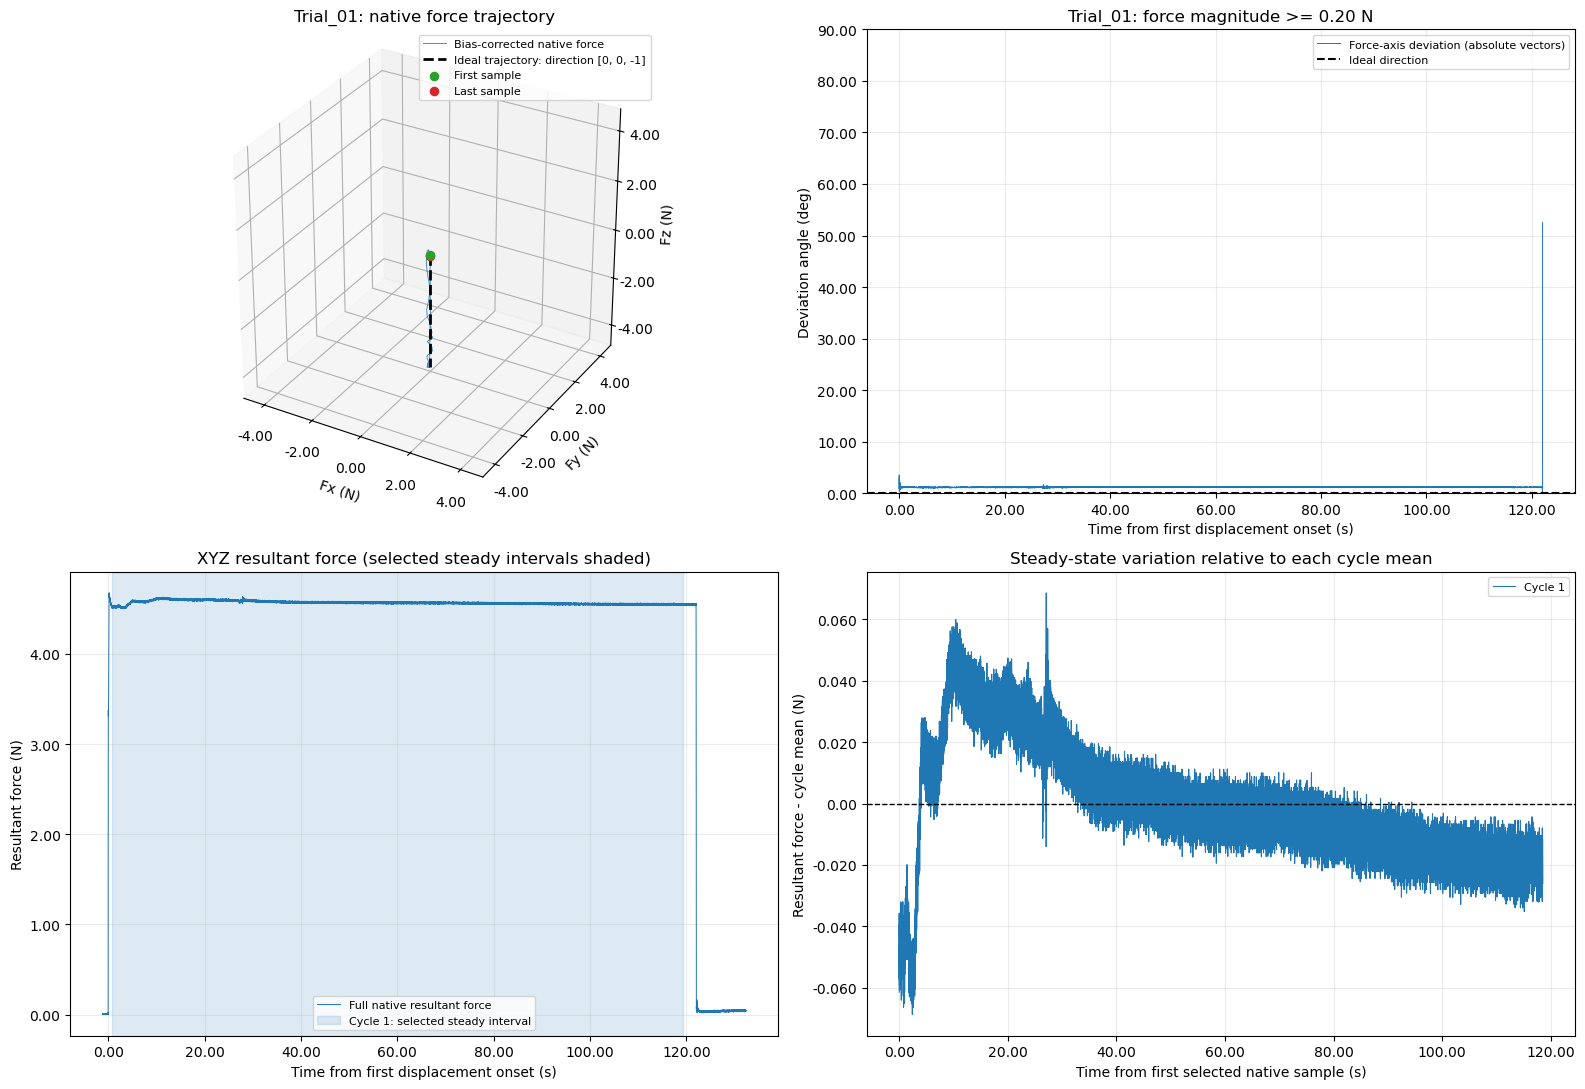

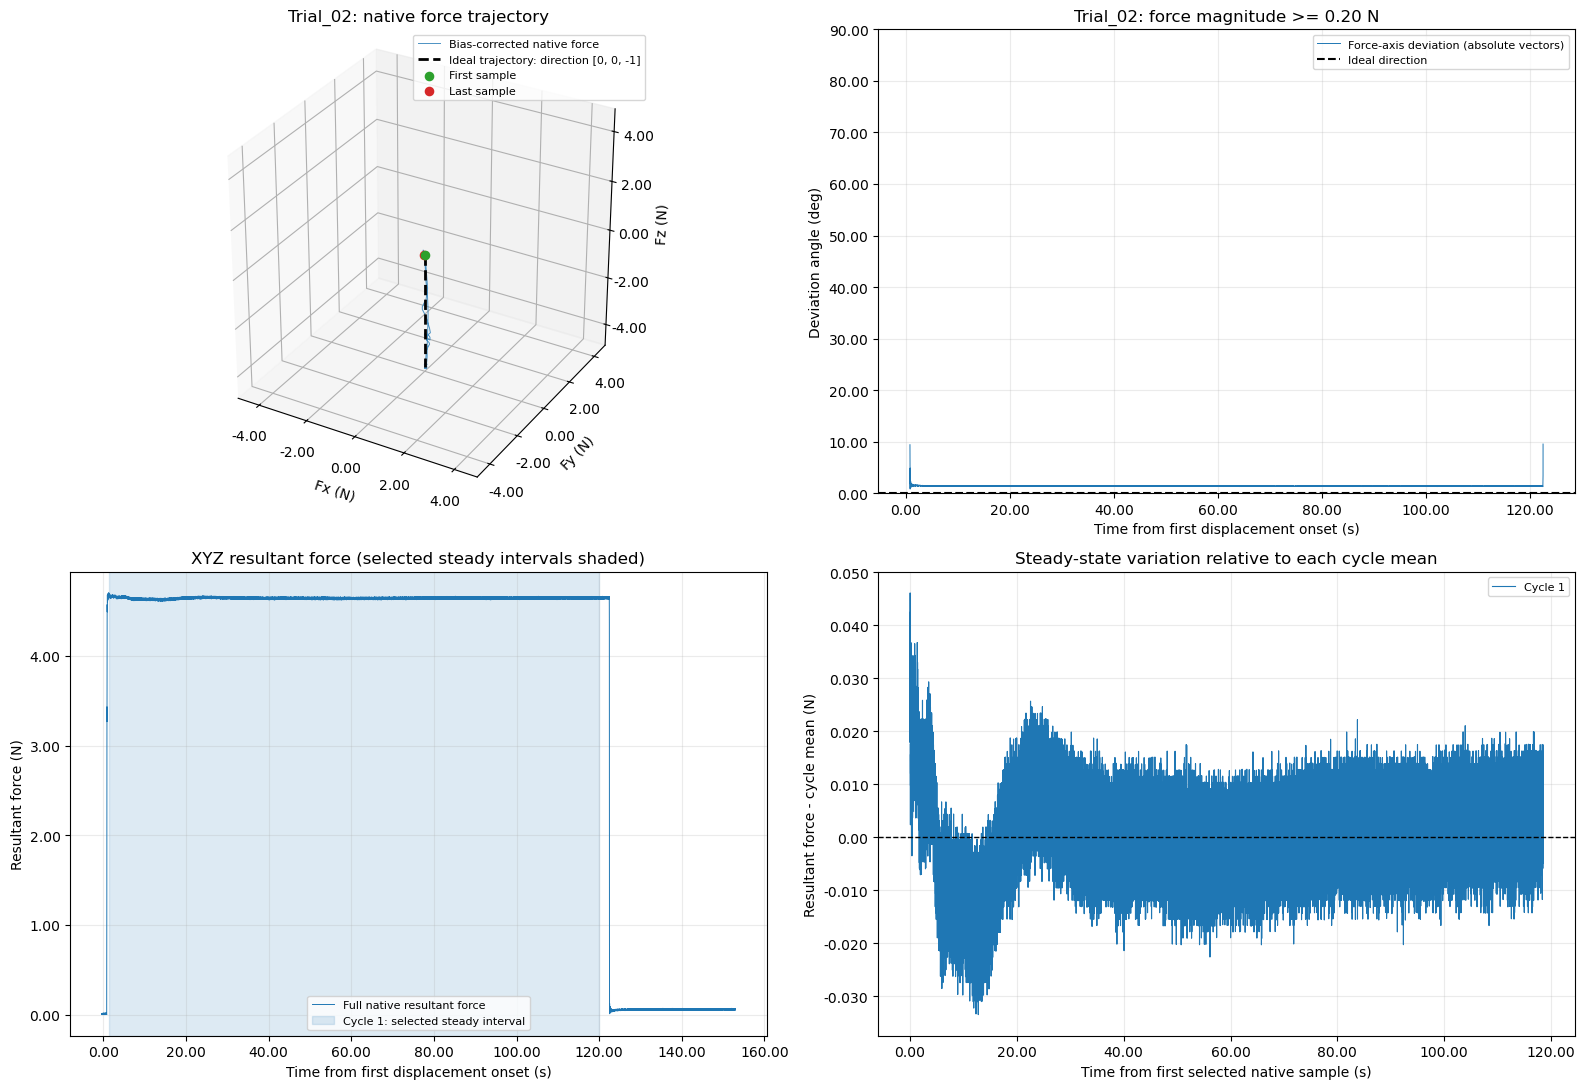

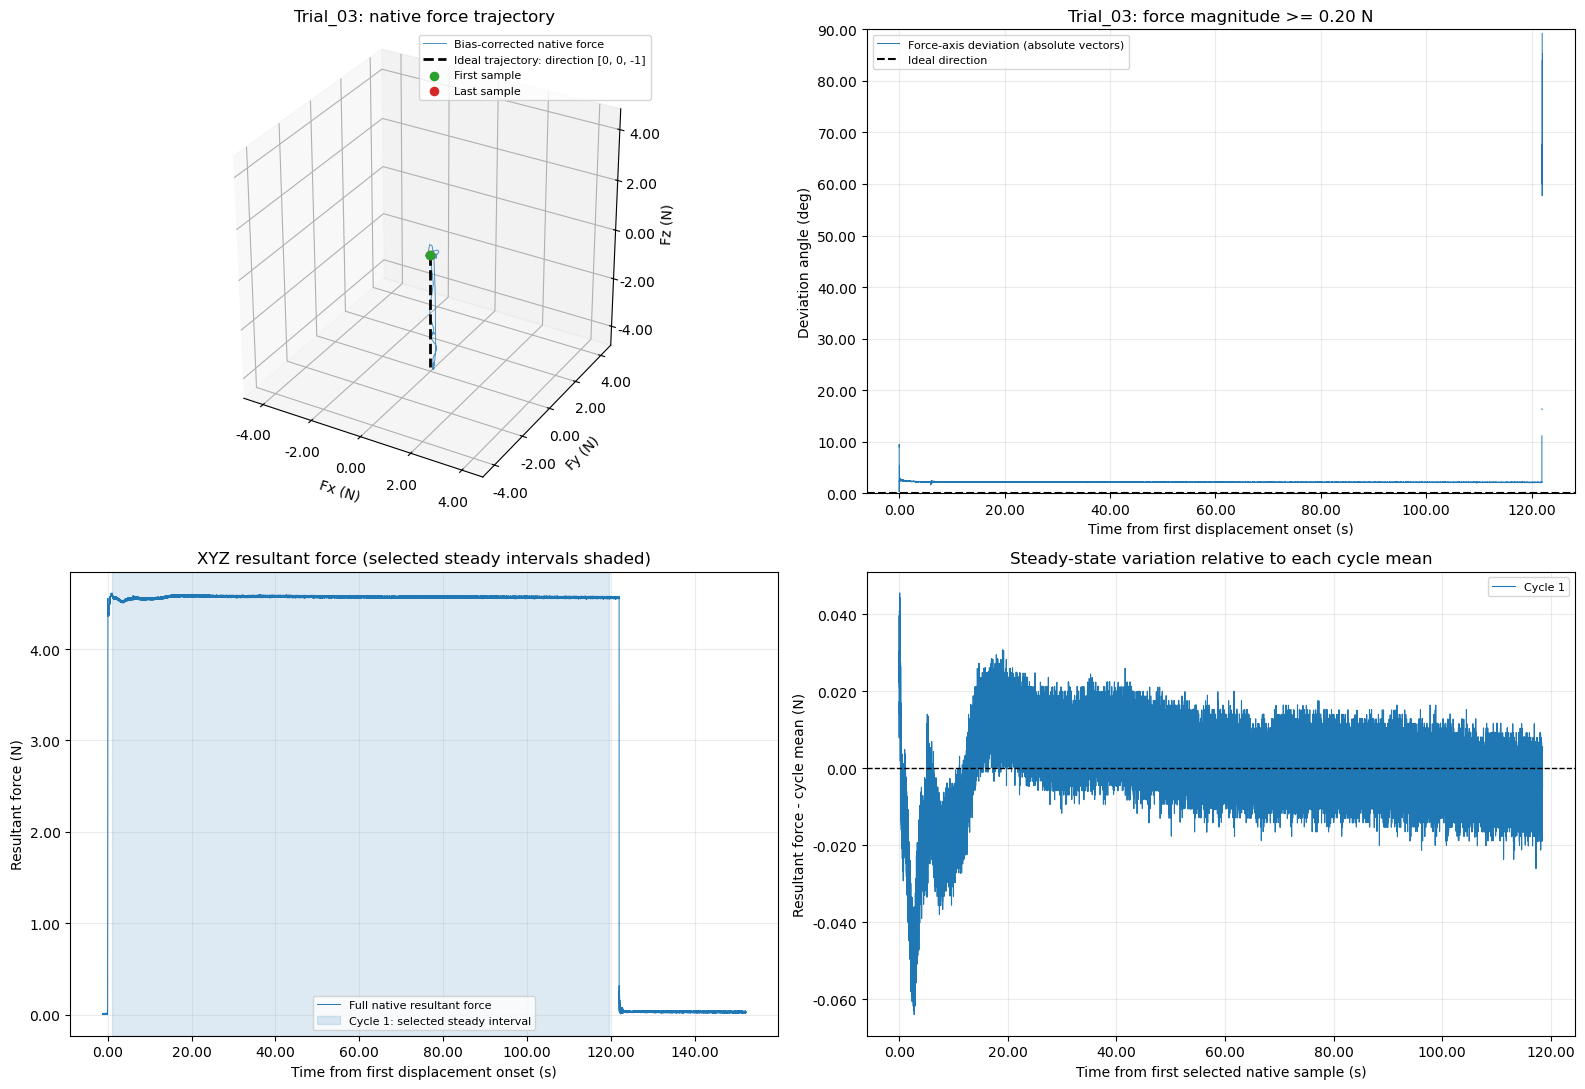

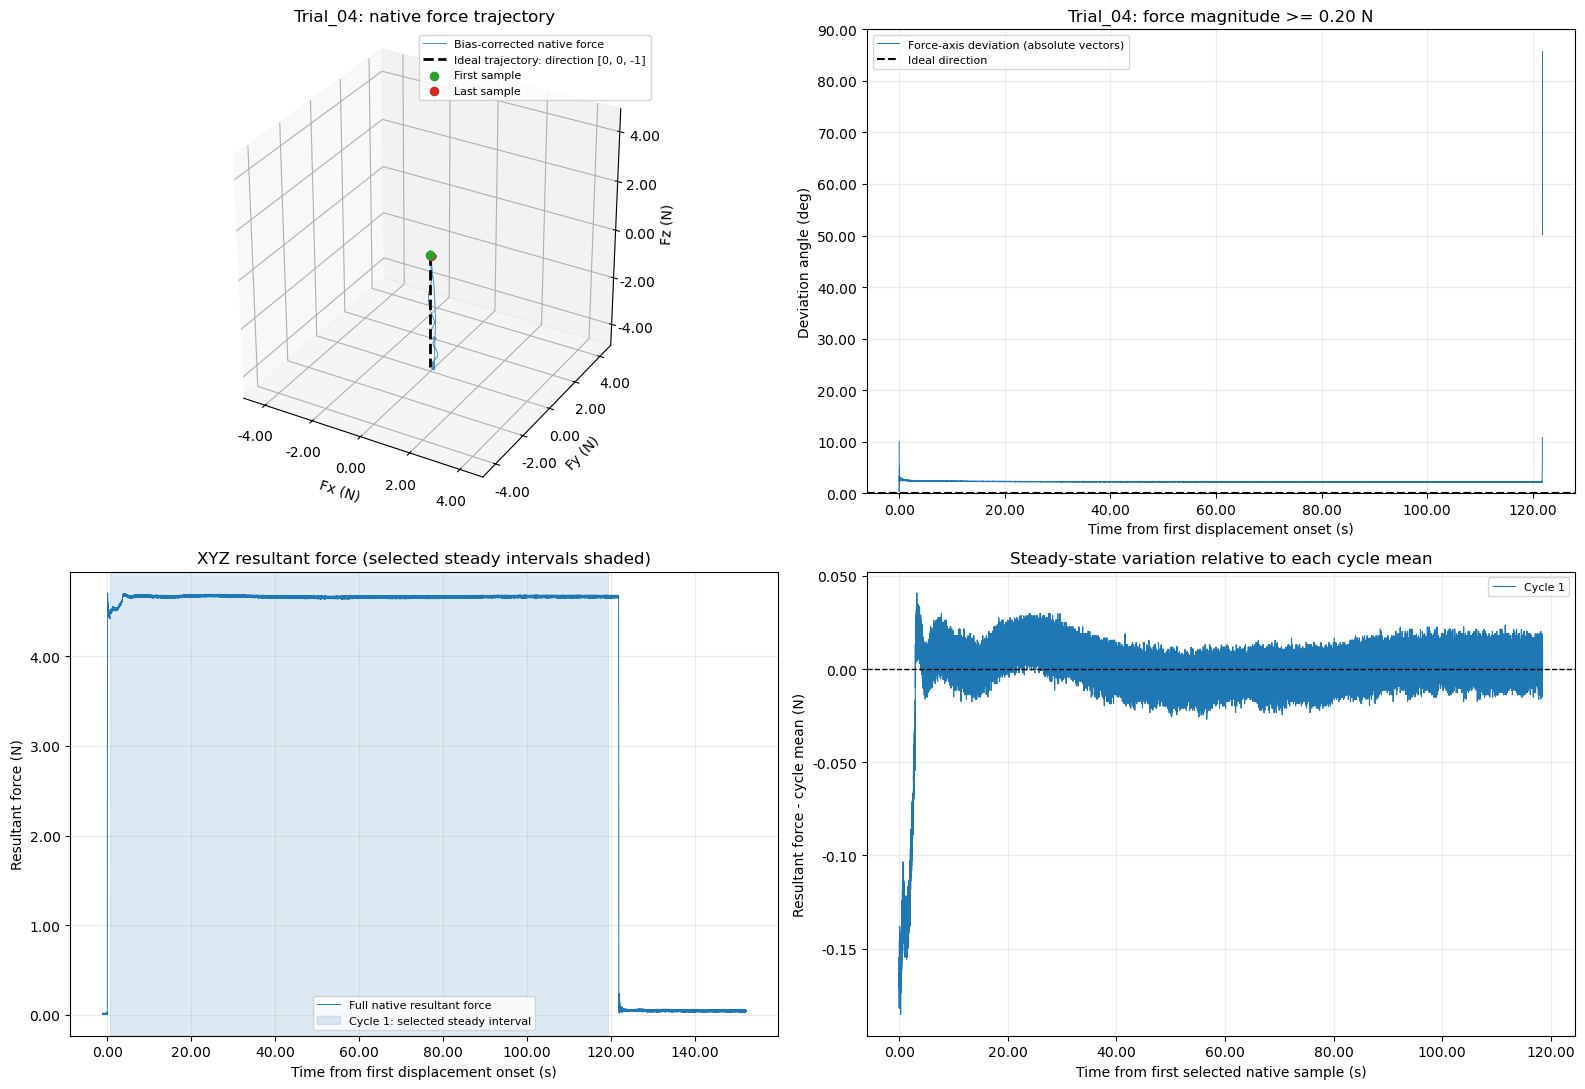

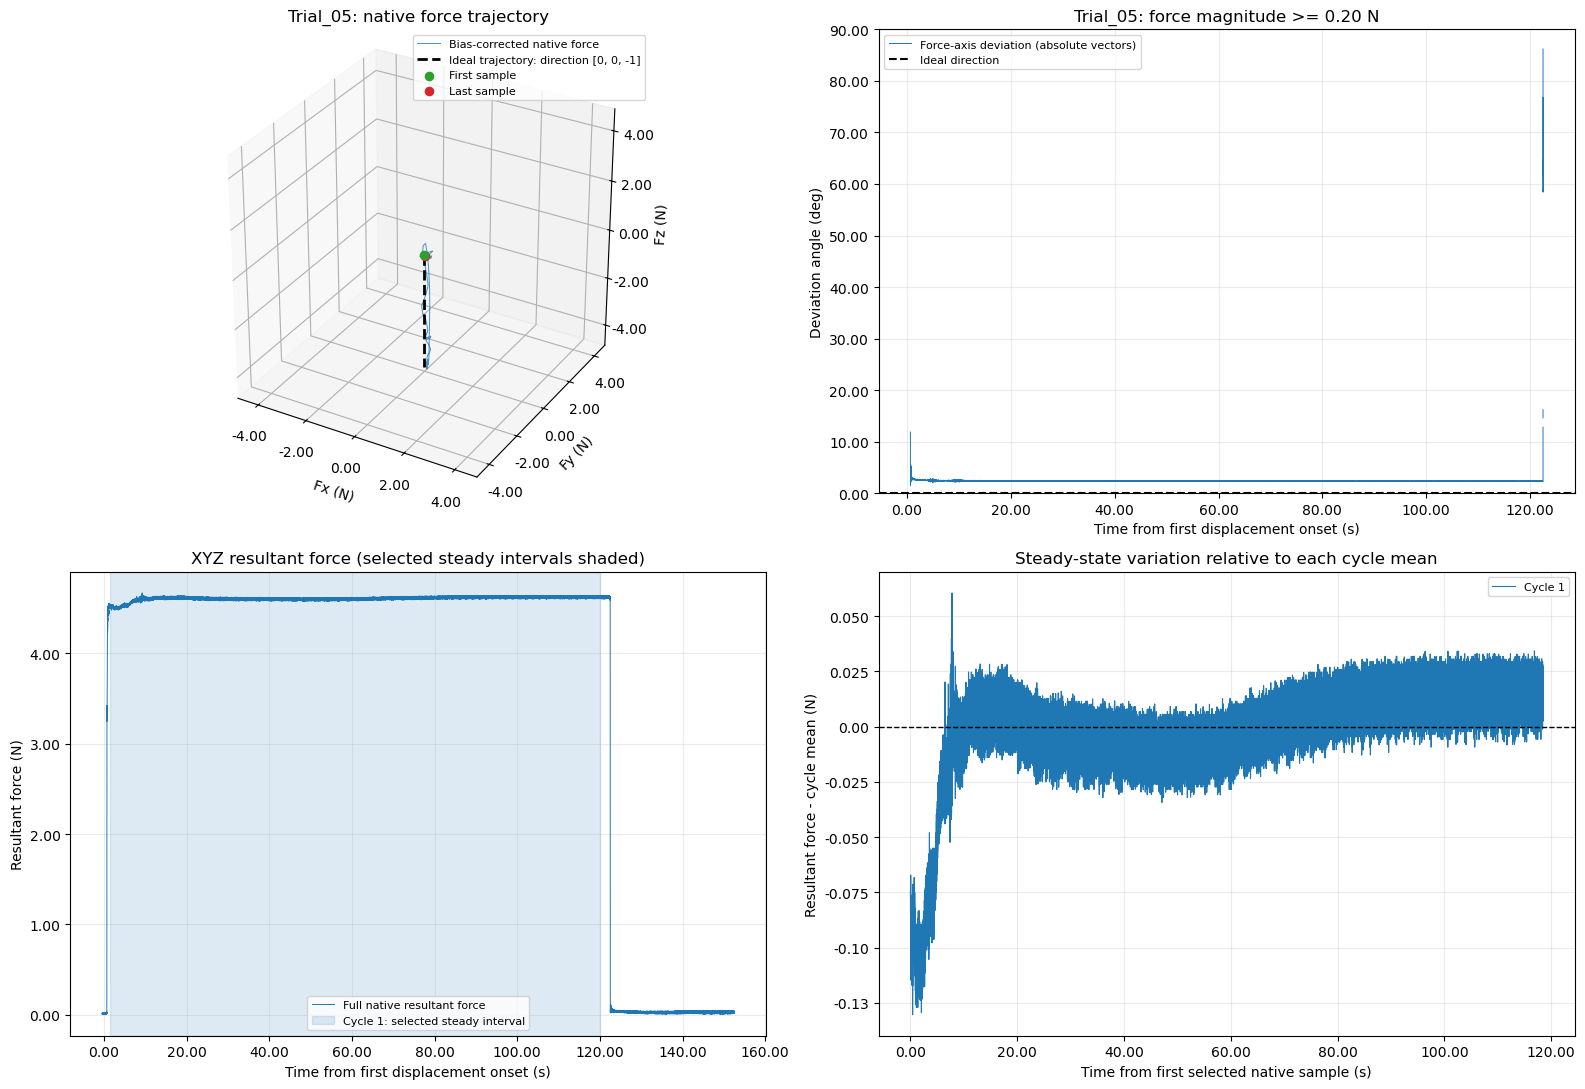

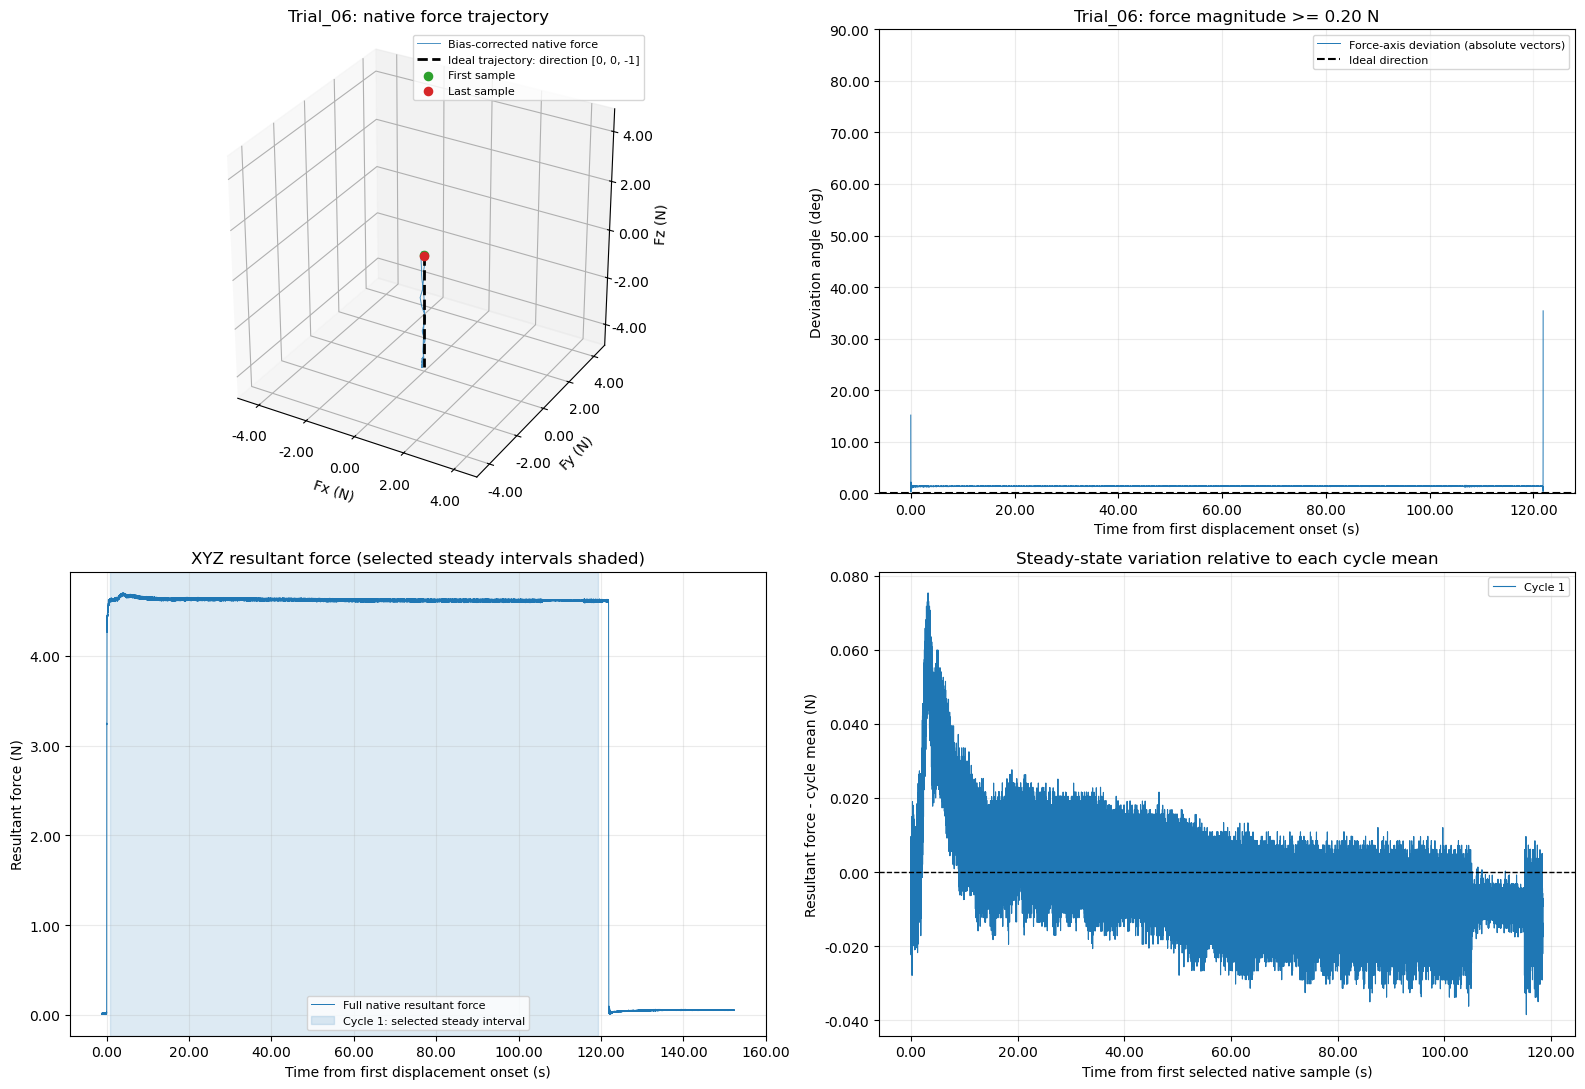

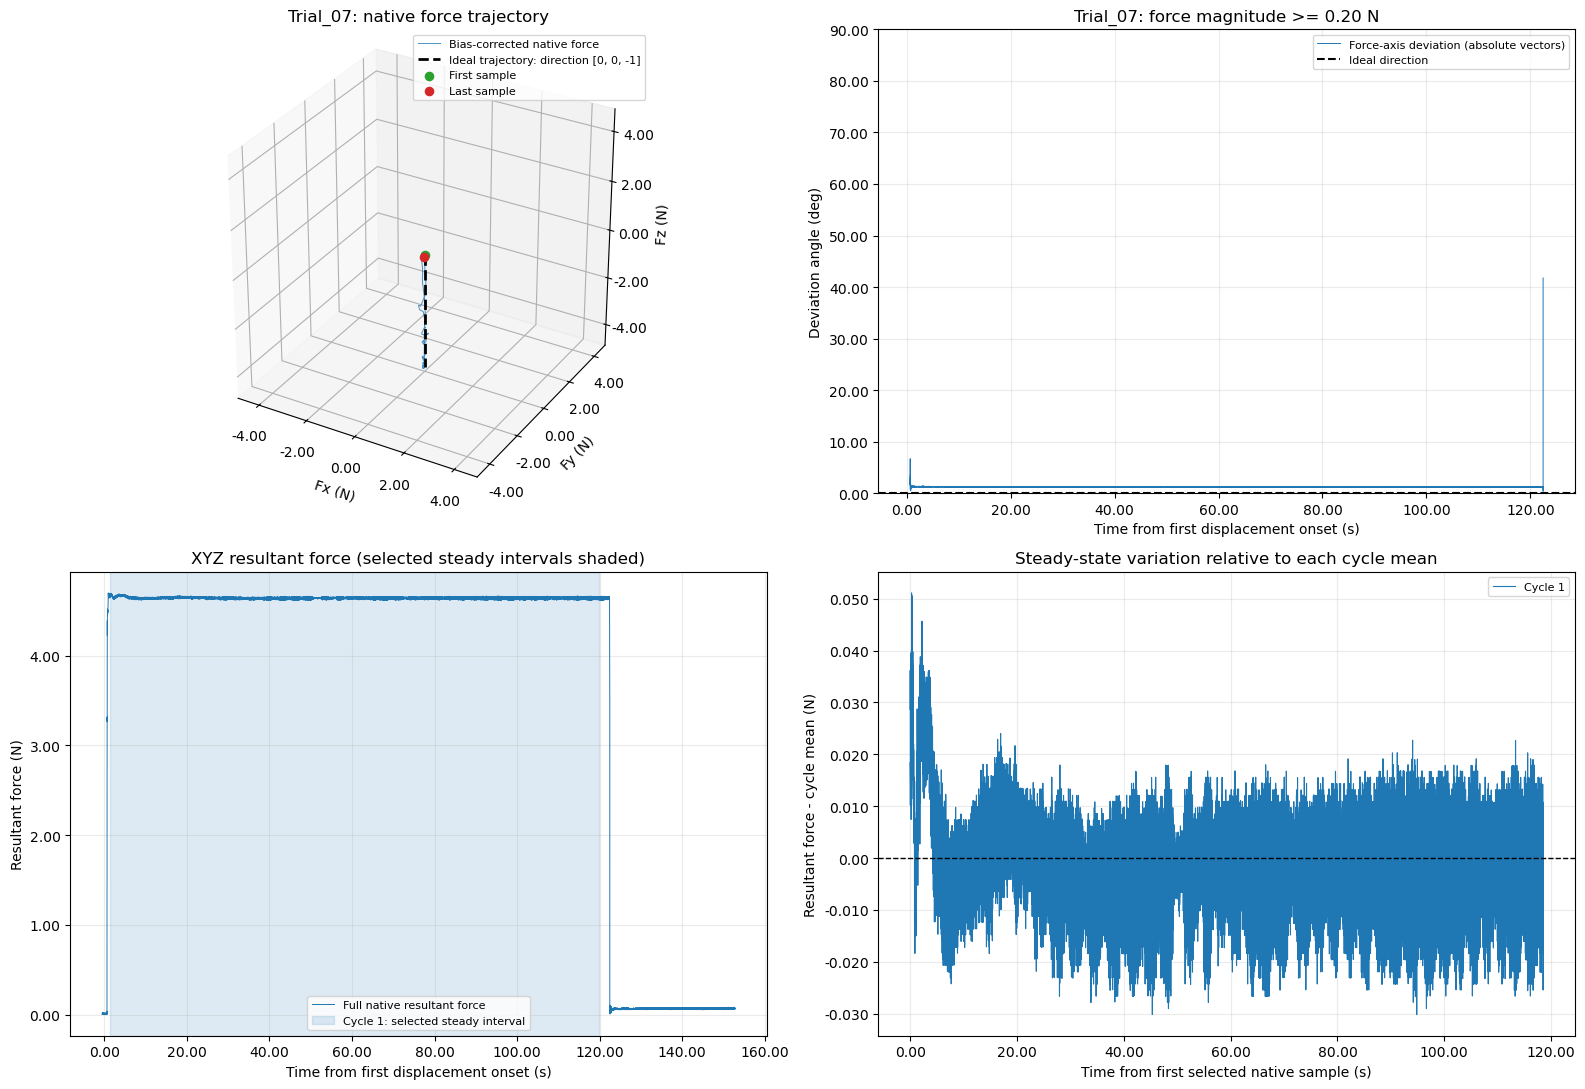

,trial,cycle,start_s,end_s,native_samples,valid_angle_samples,mean_deviation_deg
0,Trial_01,1,0.00,121.70,48680,48680,1.16
1,Trial_02,1,0.00,122.16,48864,48535,1.37
2,Trial_03,1,0.00,121.63,48654,48654,2.13
3,Trial_04,1,0.00,121.47,48587,48587,2.25
4,Trial_05,1,0.00,122.18,48873,48607,2.35
5,Trial_06,1,0.00,121.55,48590,48590,1.34
6,Trial_07,1,0.00,122.15,48854,48597,1.25


,trial,total_cycles,valid_cycles,mean_of_cycle_means_deg,std_of_cycle_means_deg
0,Trial_01,1,1,1.16,NaN
1,Trial_02,1,1,1.37,NaN
2,Trial_03,1,1,2.13,NaN
3,Trial_04,1,1,2.25,NaN
4,Trial_05,1,1,2.35,NaN
5,Trial_06,1,1,1.34,NaN
6,Trial_07,1,1,1.25,NaN


,total_cycles,valid_cycles,mean_of_cycle_means_deg,std_of_cycle_means_deg
0,7,7,1.69,0.53


,trial,cycle,start_s,end_s,native_samples,mean_resultant_force_n,std_resultant_force_n,peak_to_peak_resultant_force_n
0,Trial_01,1,0.80,119.30,47401,4.57,0.019,0.14
1,Trial_02,1,1.40,119.90,47399,4.64,0.0082,0.080
2,Trial_03,1,0.93,119.43,47450,4.57,0.011,0.11
3,Trial_04,1,0.65,119.14,47398,4.66,0.021,0.23
4,Trial_05,1,1.41,119.91,47426,4.61,0.023,0.19
5,Trial_06,1,0.73,119.23,47359,4.63,0.014,0.11
6,Trial_07,1,1.35,119.84,47402,4.64,0.0078,0.081


In [4]:
MIN_ANGLE_FORCE_N = 0.2
if not np.isfinite(MIN_ANGLE_FORCE_N) or MIN_ANGLE_FORCE_N <= 0:
    raise ValueError('MIN_ANGLE_FORCE_N must be finite and positive.')
angle_rows = []
resultant_rows = []

for result in processed:
    name = result['label']
    native = result['trial']['force']
    force_xyz = native[['Fx', 'Fy', 'Fz']].to_numpy(dtype=float, copy=True)
    baseline_mask = native.time_s.to_numpy() + result['trial']['time_zero_s'] < BASELINE_S
    if not baseline_mask.any() or not np.isfinite(force_xyz).all():
        raise ValueError(f'{name}: Native force must be finite and have initial baseline samples.')
    force_xyz -= np.mean(force_xyz[baseline_mask], axis=0)
    force_magnitude = np.linalg.norm(force_xyz, axis=1)
    deviation_deg = np.degrees(np.arctan2(
        np.hypot(force_xyz[:, 0], force_xyz[:, 1]), np.abs(force_xyz[:, 2]),
    ))
    deviation_deg[force_magnitude < MIN_ANGLE_FORCE_N] = np.nan
    angle_times = native.time_s.to_numpy()
    trace = pd.DataFrame({
        'time_s': angle_times, 'resultant_force_n': force_magnitude,
    })
    for event in result['cycles'].itertuples():
        cycle_mask = (angle_times >= event.onset_s) & (angle_times < event.release_s)
        angles = deviation_deg[cycle_mask]
        valid_angles = angles[np.isfinite(angles)]
        angle_rows.append({
            'trial': name, 'cycle': int(event.cycle),
            'start_s': event.onset_s, 'end_s': event.release_s,
            'native_samples': int(cycle_mask.sum()), 'valid_angle_samples': len(valid_angles),
            'mean_deviation_deg': valid_angles.mean() if len(valid_angles) else np.nan,
        })
    extent = max(1.0, float(force_magnitude.max()))
    fig = plt.figure(figsize=(16, 11))
    ax = fig.add_subplot(221, projection='3d')
    ax.plot(*force_xyz.T, lw=0.7, alpha=0.8, label='Bias-corrected native force')
    ax.plot([0, 0], [0, 0], [0, -extent], 'k--', lw=2,
            label='Ideal trajectory: direction [0, 0, -1]')
    ax.scatter(*force_xyz[0], color='tab:green', s=35, label='First sample')
    ax.scatter(*force_xyz[-1], color='tab:red', s=35, label='Last sample')
    ax.set(xlabel='Fx (N)', ylabel='Fy (N)', zlabel='Fz (N)',
           title=f'{name}: native force trajectory',
           xlim=(-extent, extent), ylim=(-extent, extent), zlim=(-extent, extent))
    ax.set_box_aspect((1, 1, 1))
    ax.legend(fontsize=8)
    angle_ax = fig.add_subplot(222)
    angle_ax.plot(angle_times, deviation_deg, lw=0.7, label='Force-axis deviation (absolute vectors)')
    angle_ax.axhline(0, color='black', ls='--', label='Ideal direction')
    angle_ax.set(xlabel='Time from first displacement onset (s)', ylabel='Deviation angle (deg)', ylim=(0, 90),
                 title=f'{name}: force magnitude >= {format_fractional_digits(MIN_ANGLE_FORCE_N)} N')
    angle_ax.grid(True, alpha=0.25)
    angle_ax.legend(fontsize=8)
    resultant_ax = fig.add_subplot(223)
    variation_ax = fig.add_subplot(224)
    resultant_ax.plot(trace.time_s, trace.resultant_force_n, lw=0.7,
                      color='tab:blue', label='Full native resultant force')
    if ENABLE_STEADY_STATE_SEGMENTATION:
        for event in result['cycles'].itertuples():
            cycle = int(event.cycle)
            start, end = event.export_start_s, event.export_end_s
            selected = trace.loc[(trace.time_s >= start) & (trace.time_s < end)]
            if len(selected) < 2 or not np.isfinite(selected.resultant_force_n).all():
                raise ValueError(f'{name} cycle {cycle}: Need at least two finite native force samples.')
            resultant = selected.resultant_force_n.to_numpy()
            mean_force = resultant.mean()
            delta_force = resultant - mean_force
            resultant_rows.append({
                'trial': name, 'cycle': cycle, 'start_s': start, 'end_s': end,
                'native_samples': len(selected),
                'mean_resultant_force_n': mean_force,
                'std_resultant_force_n': resultant.std(ddof=1),
                'peak_to_peak_resultant_force_n': np.ptp(resultant),
            })
            label = f'Cycle {cycle}'
            line, = variation_ax.plot(selected.time_s - selected.time_s.iloc[0], delta_force,
                                     lw=0.8, label=label)
            resultant_ax.axvspan(start, end, color=line.get_color(), alpha=0.15, label=f'{label}: selected steady interval')
    resultant_ax.set(title='XYZ resultant force (selected steady intervals shaded)',
                xlabel='Time from first displacement onset (s)', ylabel='Resultant force (N)')
    if not ENABLE_STEADY_STATE_SEGMENTATION:
        variation_ax.text(0.5, 0.5, 'Enable steady-state segmentation to inspect steady variation.',
                          ha='center', va='center', transform=variation_ax.transAxes)
    variation_ax.axhline(0, color='black', ls='--', lw=1)
    variation_ax.set(title='Steady-state variation relative to each cycle mean',
                xlabel='Time from first selected native sample (s)',
                ylabel='Resultant force - cycle mean (N)')
    for axis in (resultant_ax, variation_ax):
        axis.grid(True, alpha=0.25)
        if axis.get_legend_handles_labels()[0]:
            axis.legend(fontsize=8)
    show_figure(fig, f"{result['name']}_native_force_diagnostics.png", result['output_dir'])

cycle_deviation_summary = pd.DataFrame(angle_rows)
display(cycle_deviation_summary)
cycle_means = cycle_deviation_summary['mean_deviation_deg']
overall_deviation_summary = pd.DataFrame([{
    'total_cycles': len(cycle_means), 'valid_cycles': int(cycle_means.count()),
    'mean_of_cycle_means_deg': cycle_means.mean(),
    'std_of_cycle_means_deg': cycle_means.std(ddof=1),
}])
trial_deviation_summary = cycle_deviation_summary.groupby('trial', sort=False).agg(
    total_cycles=('cycle', 'size'), valid_cycles=('mean_deviation_deg', 'count'),
    mean_of_cycle_means_deg=('mean_deviation_deg', 'mean'),
    std_of_cycle_means_deg=('mean_deviation_deg', 'std'),
).reset_index()
display(trial_deviation_summary)
display(overall_deviation_summary)

steady_resultant_summary = pd.DataFrame(resultant_rows)
if ENABLE_STEADY_STATE_SEGMENTATION:
    display(steady_resultant_summary)


## Check synchronization, spike removal, and export boundaries

Colored shading shows the intervals retained for export. Dotted lines mark export starts and dashed lines mark release commands. With steady-state segmentation enabled, light gray shading shows the excluded loading and settling interval. With it disabled, the retained interval spans the full detected cycle. Gray LVDT traces show valid native data before spike repair; the cleaned signal is interpolated at 200 Hz. Review the thresholds if real loading steps are marked as spikes. For force-only cycle detection, release boundaries are estimates and the cycle-detection release guard still applies.

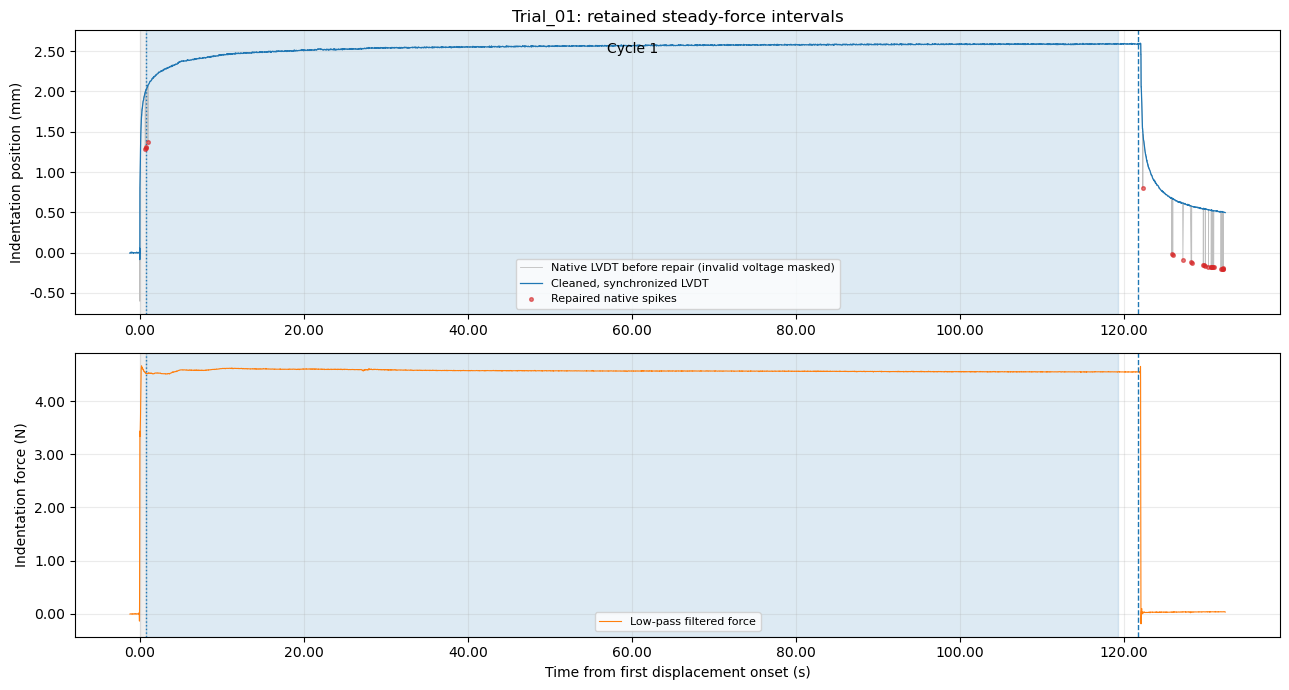

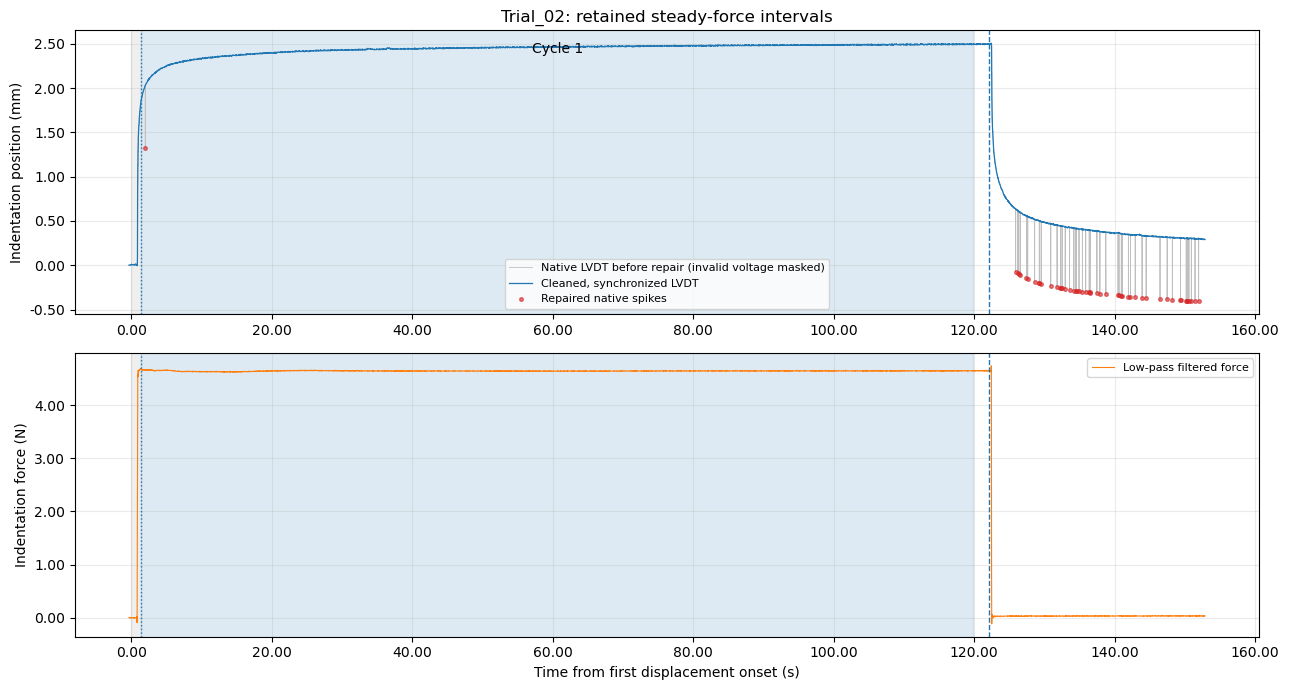

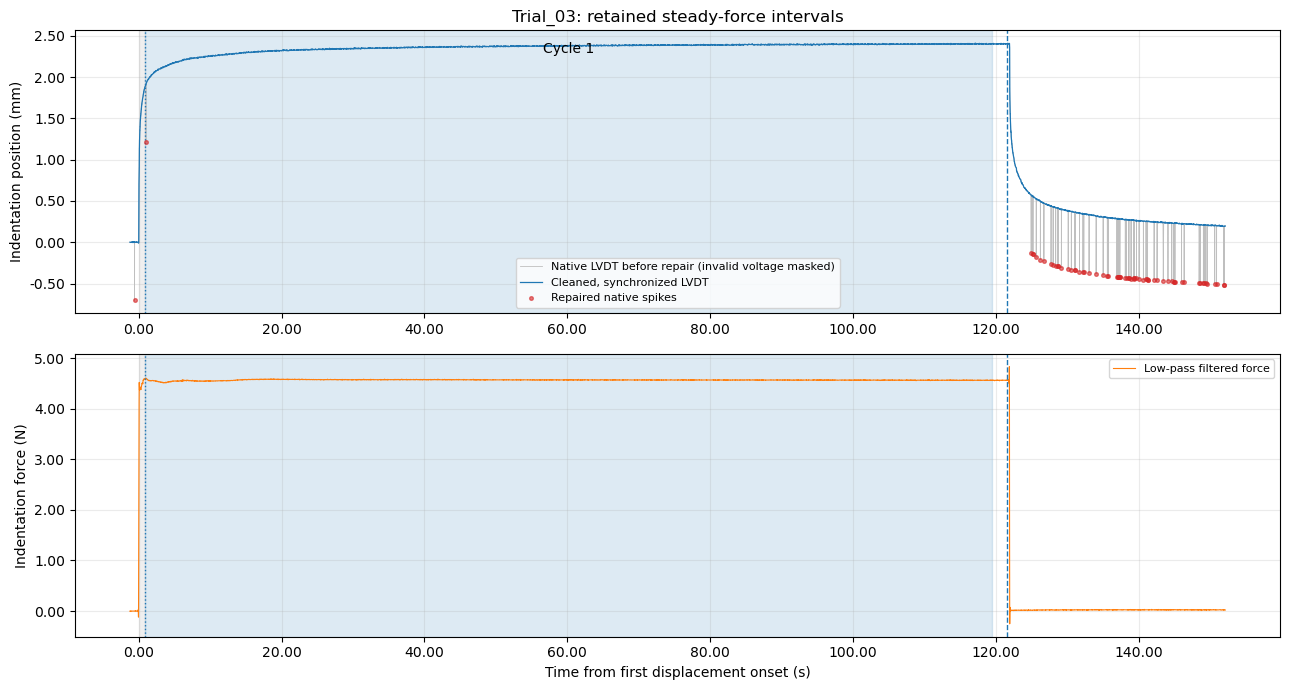

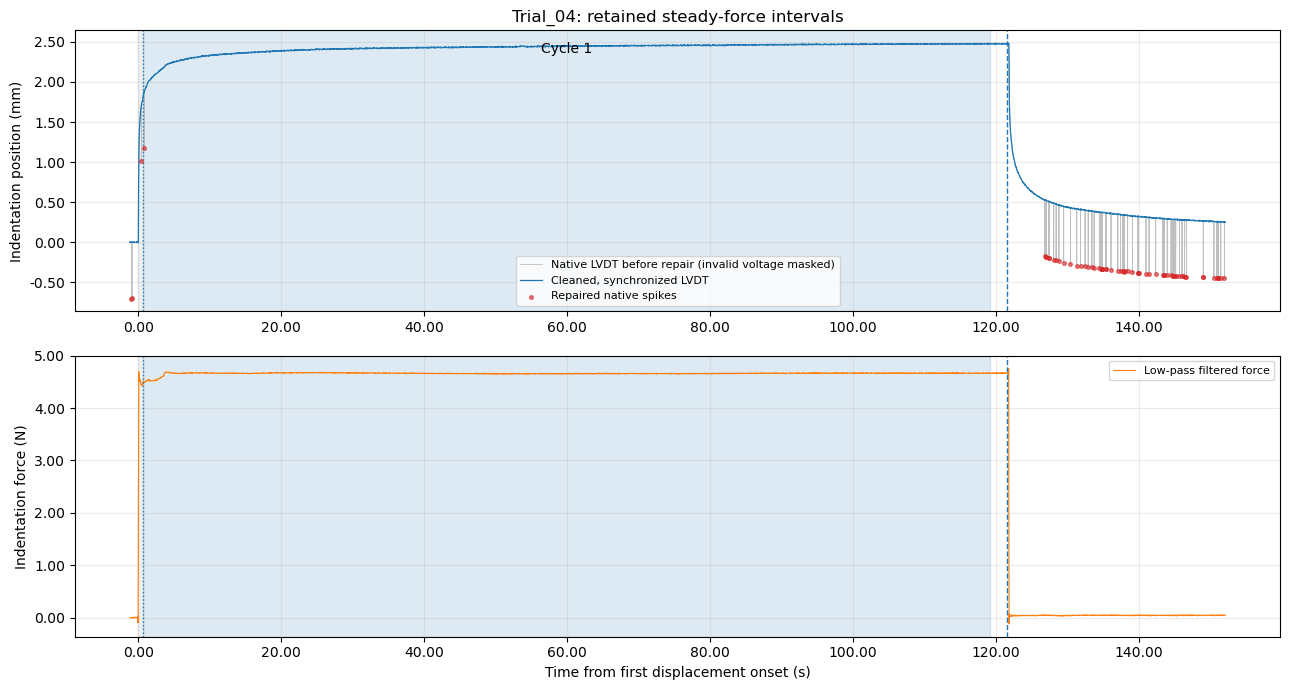

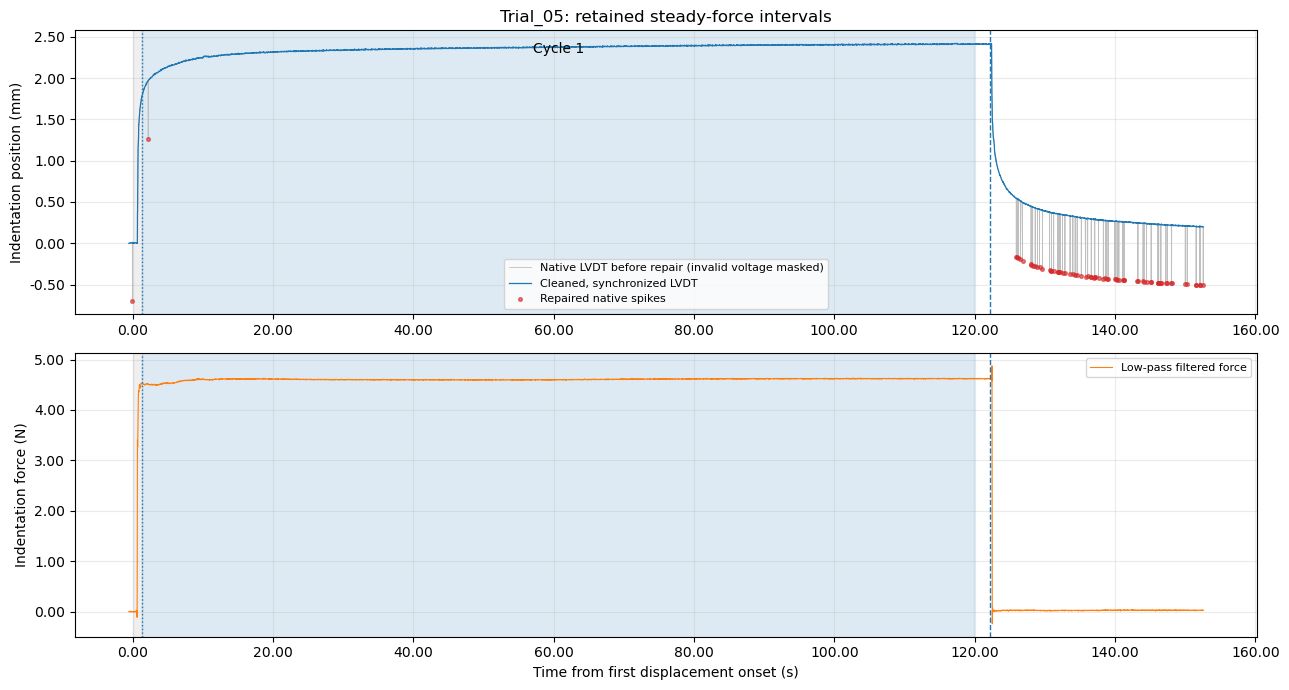

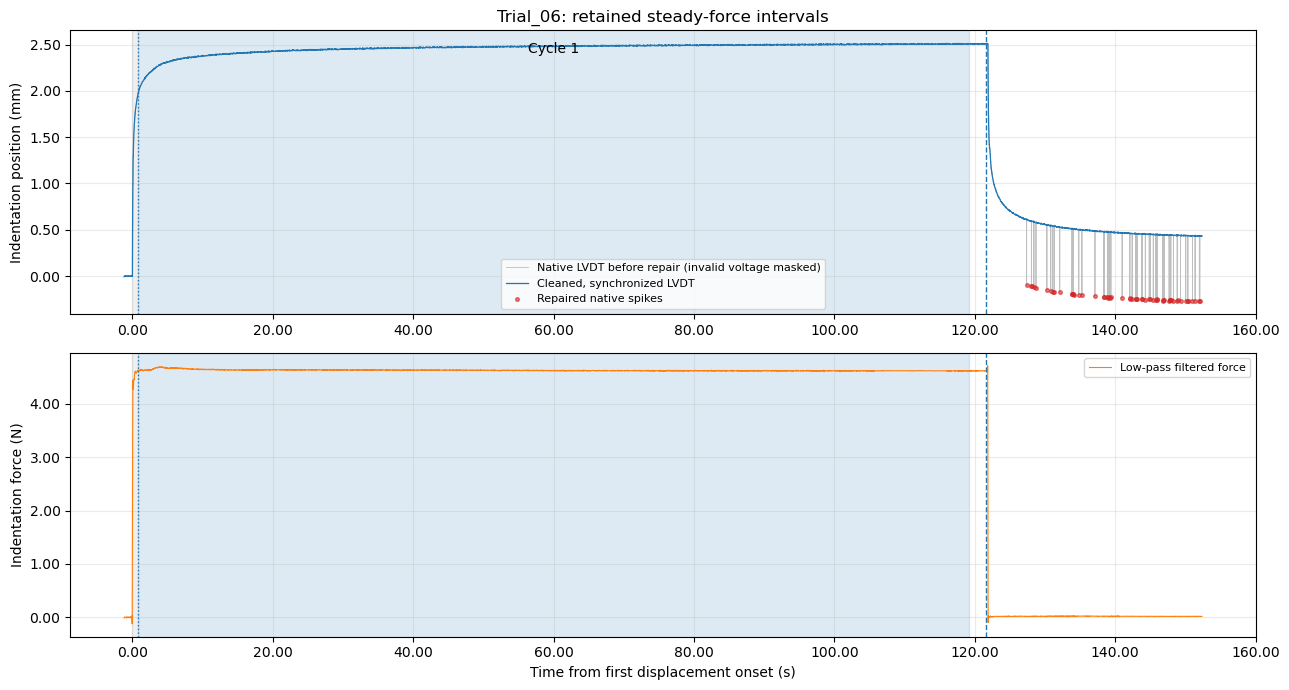

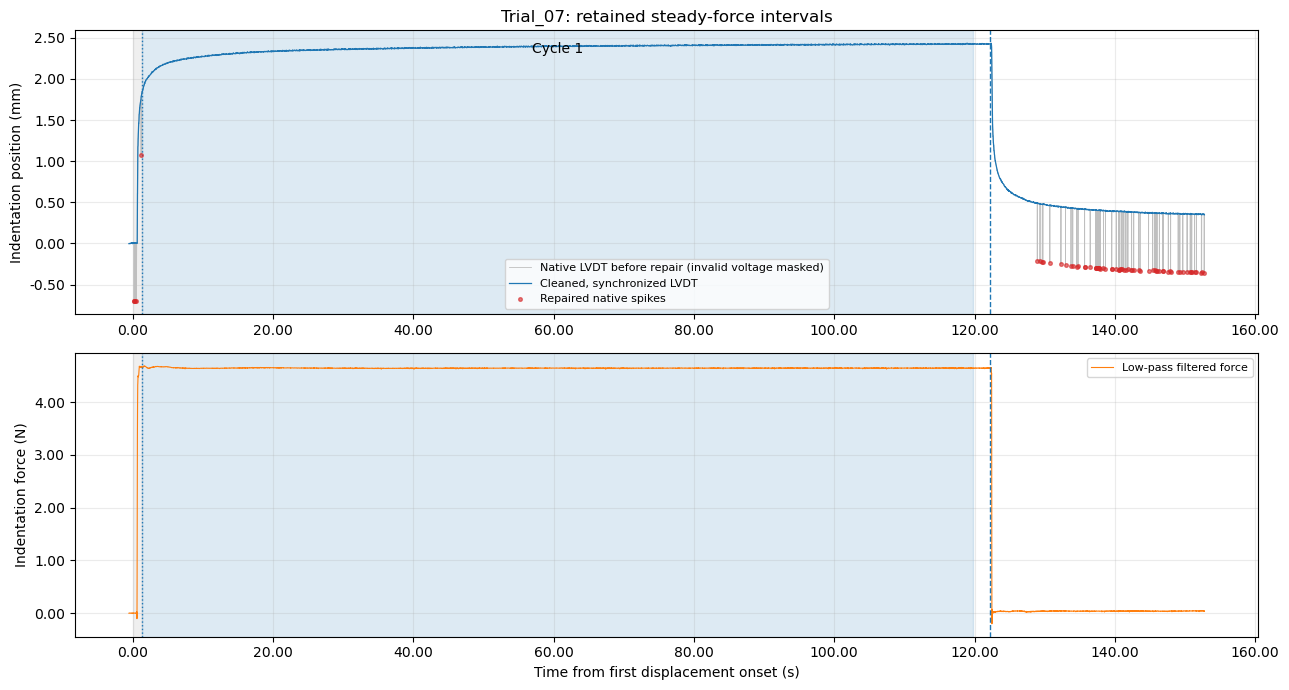

In [5]:
for result in processed:
    trial, cycles = result['trial'], result['cycles']
    sync, lvdt = trial['sync'], trial['lvdt']
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=False)
    axes[0].plot(lvdt.time_s, lvdt.displacement_before_despike_mm,
                 color='0.75', lw=0.6, label='Native LVDT before repair (invalid voltage masked)')
    axes[0].plot(sync.time_s, sync.displacement_mm, color='tab:blue', lw=0.9,
                 label='Cleaned, synchronized LVDT')
    spike = lvdt.displacement_spike
    axes[0].scatter(lvdt.loc[spike, 'time_s'], lvdt.loc[spike, 'displacement_before_despike_mm'],
                    color='tab:red', s=7, alpha=0.6, label='Repaired native spikes', zorder=3)
    axes[1].plot(sync.time_s, sync.force_n, color='tab:orange', lw=0.8, label='Low-pass filtered force' if ENABLE_FORCE_LOWPASS else 'Synchronized force')
    # axes[1].set_xlim(.0, 1.0)
    for event in cycles.itertuples():
        color = plt.get_cmap('tab10')((event.cycle - 1) % 10)
        for axis in axes:
            axis.axvspan(event.onset_s, event.export_start_s, color='0.5', alpha=0.12)
            axis.axvspan(event.export_start_s, event.export_end_s, color=color, alpha=0.15)
            axis.axvline(event.export_start_s, color=color, ls=':', lw=1)
            axis.axvline(event.release_s, color=color, ls='--', lw=1)
        axes[0].text((event.export_start_s + event.export_end_s) / 2, 0.96,
                     f'Cycle {event.cycle}', transform=axes[0].get_xaxis_transform(),
                     ha='center', va='top')
    axes[0].set(title=f"{result['label']}: retained {segment_label} intervals",
                 ylabel='Indentation position (mm)')
    axes[1].set(xlabel='Time from first displacement onset (s)', ylabel='Indentation force (N)')
    for axis in axes:
        axis.legend(loc='best', fontsize=8)
    show_figure(fig, f"{result['name']}_synchronization.png", result['output_dir'])

## Visualize every exported segment

Columns show raw trials, with force and displacement sharing the same elapsed time axis from each exported cycle's first retained sample. Loading and settling are included when `ENABLE_STEADY_STATE_SEGMENTATION = False`; steady-state mode trims them according to its detection settings and offsets. The overlay compares all retained segments within each raw trial.

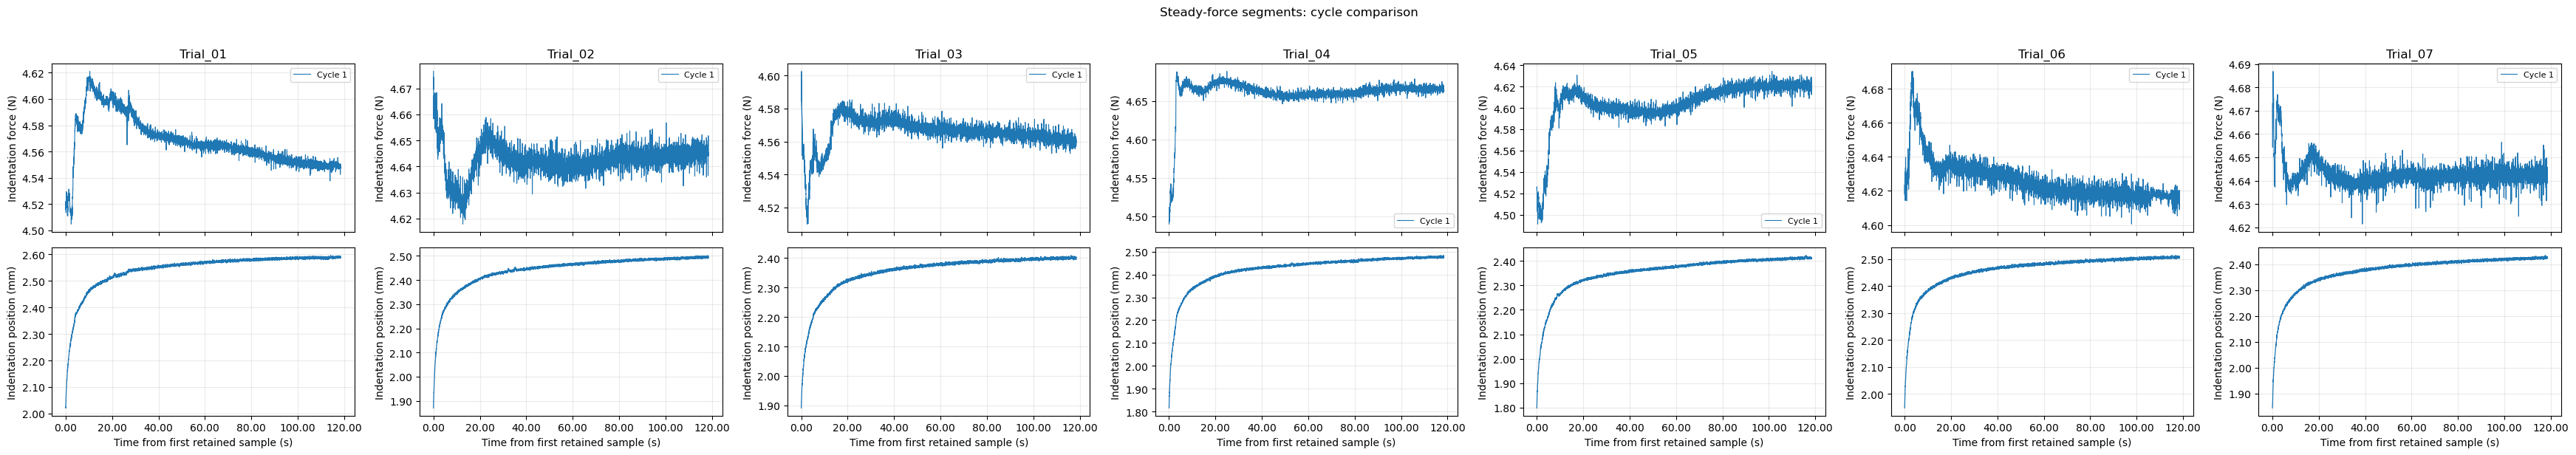

In [6]:
for output_dir in OUTPUT_DIRS:
    sample_processed = [result for result in processed if result['output_dir'] == output_dir]
    fig, axes = plt.subplots(2, len(sample_processed), figsize=(5 * len(sample_processed), 6),
                             sharex='col', squeeze=False)
    for column, result in enumerate(sample_processed):
        for cycle_number, frame in result['extracted']:
            time = frame[OUTPUT_COLUMNS[0]]
            line, = axes[0, column].plot(time, frame[OUTPUT_COLUMNS[2]], lw=0.8, label=f'Cycle {cycle_number}')
            axes[1, column].plot(time, frame[OUTPUT_COLUMNS[1]], lw=0.9, color=line.get_color())
        axes[0, column].set(title=result['label'], ylabel='Indentation force (N)')
        axes[1, column].set(xlabel='Time from first retained sample (s)', ylabel='Indentation position (mm)')
        axes[0, column].legend(fontsize=8)
    fig.suptitle(f'{segment_label.capitalize()} segments: cycle comparison', y=1.02)
    show_figure(fig, 'all_cycle_overlays.png', output_dir)

## Export synchronized cycle CSVs

All selected trials and export intervals have been validated before writing. Each cycle is saved in `Indentation_01/`, `Indentation_02/`, etc., under `OUTPUT_DIR`, retaining filenames such as `Trial_01_1.csv`. Running this cell overwrites cycle CSVs for the selected raw trials and removes their obsolete numbered exports from the output root and indentation folders. Both segmentation modes use the same output paths. Raw measurements remain untouched. `_cycle_manifest.csv` stays in `OUTPUT_DIR` and stores output-relative file paths, segmentation mode, export boundaries, original timing, baseline, and cycle metadata separately so that every cycle CSV retains exactly the required three columns. Steady-force diagnostics are included only when that mode is enabled.

`data_process/Load_Profile-Creep_Curve_Fit_Kelvin.ipynb` fits a constant-force hold response. Full-load exports include the loading ramp and may include zero or negative baseline-corrected force; select a steady hold or use a force-history model before fitting those exports.

In [7]:
exported_paths = []
for result in processed:
    output_dir = result['output_dir']
    output_dir.mkdir(parents=True, exist_ok=True)
    expected_paths = {
        output_dir / f"Indentation_{cycle_number:02d}" / f"{result['name']}_{cycle_number}.csv"
        for cycle_number, _ in result['extracted']
    }
    for cycle_number, frame in result['extracted']:
        cycle_dir = output_dir / f"Indentation_{cycle_number:02d}"
        cycle_dir.mkdir(parents=True, exist_ok=True)
        output_path = cycle_dir / f"{result['name']}_{cycle_number}.csv"
        frame.assign(**{column: frame[column]
                        for column in OUTPUT_COLUMNS[1:]}).to_csv(output_path, index=False)
        exported_paths.append(output_path)
        print(f'{output_path.relative_to(PROJECT_ROOT)}: {len(frame):,} rows at {SAMPLING_HZ:g} Hz')
    old_paths = list(output_dir.glob(f"{result['name']}_*.csv"))
    old_paths.extend(output_dir.glob(f"Indentation_[0-9][0-9]*/{result['name']}_*.csv"))
    for old_path in old_paths:
        suffix = old_path.stem[len(result['name']) + 1:]
        if suffix.isdigit() and old_path not in expected_paths:
            old_path.unlink()

for sample_dir, output_dir in zip(SAMPLE_DIRS, OUTPUT_DIRS):
    sample_summary = cycle_summary.loc[cycle_summary['sample'].eq(sample_dir.name)]
    manifest_path = output_dir / '_cycle_manifest.csv'
    if manifest_path.exists():
        previous = pd.read_csv(manifest_path, dtype={'origin_ns': 'int64',
                                                    'acquisition_origin_ns': 'Int64'})
        previous = previous.loc[~previous.source_trial.isin(sample_summary.source_trial)]
        manifest = pd.concat([previous, sample_summary], ignore_index=True)
    else:
        manifest = sample_summary
    manifest.assign(**{column: manifest[column]
                       for column in manifest.columns if column.endswith(('_n', '_mm'))
                       }).to_csv(manifest_path, index=False)
print(f'Saved {len(exported_paths)} {segment_label} cycle CSVs across {len(SAMPLE_DIRS)} sample(s).')
display(processed[0]['extracted'][0][1].head())

data/Clindent_Data/400g/Black_Gel/sample_01/synchronized/Indentation_01/Trial_01_1.csv: 23,700 rows at 200 Hz
data/Clindent_Data/400g/Black_Gel/sample_01/synchronized/Indentation_01/Trial_02_1.csv: 23,700 rows at 200 Hz
data/Clindent_Data/400g/Black_Gel/sample_01/synchronized/Indentation_01/Trial_03_1.csv: 23,700 rows at 200 Hz
data/Clindent_Data/400g/Black_Gel/sample_01/synchronized/Indentation_01/Trial_04_1.csv: 23,700 rows at 200 Hz
data/Clindent_Data/400g/Black_Gel/sample_01/synchronized/Indentation_01/Trial_05_1.csv: 23,700 rows at 200 Hz
data/Clindent_Data/400g/Black_Gel/sample_01/synchronized/Indentation_01/Trial_06_1.csv: 23,700 rows at 200 Hz
data/Clindent_Data/400g/Black_Gel/sample_01/synchronized/Indentation_01/Trial_07_1.csv: 23,700 rows at 200 Hz
Saved 7 steady-force cycle CSVs across 1 sample(s).


,"Time, s","Indentation Position, mm","Indentation Force, N"
0,0.00,2.024,4.52
1,0.0050,2.021,4.52
2,0.010,2.021,4.52
3,0.015,2.021,4.52
4,0.020,2.021,4.52
